<a href="https://colab.research.google.com/github/nocked115/ai-lab/blob/main/%20%20%20cvwletter/week4-ldm/01_sd_pretrained_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4주차 LDM 실습 — Stable Diffusion으로 LDM 뜯어보기

논문에서 본 부품 세 개를 Stable Diffusion 안에서 직접 확인한다.

| 부품 | 논문 | Stable Diffusion 코드 |
|---|---|---|
| 오토인코더 `E`, `D` | 3.1 | `pipe.vae` |
| UNet `ε_θ` | 3.2 | `pipe.unet` |
| 텍스트 인코더 `τ_θ` | 3.3 | `pipe.text_encoder` (CLIP) |

**시작 전:** 메뉴 `런타임 → 런타임 유형 변경 → T4 GPU` 선택

## 0. 설치 & 모델 불러오기 (처음 한 번, 2~3분)

In [1]:
!pip -q install diffusers transformers accelerate

- diffusers: Hugging Face의 diffusion 모델 라이브러리예요. Stable Diffusion이 여기 들어 있어요.
- transformers: 텍스트 인코더(CLIP)를 돌리는 데 필요해요.
- accelerate: GPU에 모델을 효율적으로 올려 줘요

In [2]:
import torch, time
from diffusers import StableDiffusionPipeline
from diffusers.utils import make_image_grid

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
).to("cuda")
pipe.set_progress_bar_config(disable=True)

def gen(prompt, steps=25, cfg=7.5, seed=0, **kw):
    g = torch.Generator("cuda").manual_seed(seed)   # seed 고정 → 같은 시작 노이즈 z_T
    return pipe(prompt, num_inference_steps=steps, guidance_scale=cfg, generator=g, **kw).images[0]

prompt = "a cute cat wearing an astronaut suit, stars in the background, digital art"

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

```
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
).to("cuda")
```

pipe 안에 LDM 부품 세 개가 한 번에 들어 있어요.
- pipe.vae = 오토인코더 E, D (3.1)
- pipe.unet = 노이즈 맞히는 UNet ε_θ (3.2)
- pipe.text_encoder = 텍스트 인코더 τ_θ (3.3)

float16: 숫자를 절반 정밀도로 저장해서 메모리를 아껴요. T4 GPU에 올리려면 필요해요.

.to("cuda"): 모델을 GPU로 옮겨요.




```
def gen(prompt, steps=25, cfg=7.5, seed=0, **kw):
    g = torch.Generator("cuda").manual_seed(seed)
```

- 그림 만드는 함수를 하나 정의해 둔 거예요.
- seed: 시작 노이즈 z_T를 정하는 번호예요. 같은 seed면 같은 노이즈에서 출발하니까, 뒤에서 steps나 CFG만 바꿔 비교할 때 공정한 비교가 돼요.



```
prompt = "a cute cat wearing an astronaut suit, stars in the background, digital art"
```

그릴 그림 설명이에요. (영어가 잘 먹어요. CLIP 텍스트 인코더가 영어로 학습됐거든요.)



## 1. 이미지 1장 생성 ✅ 체크리스트 1

내부에서 일어나는 일 (논문 Figure 3 아랫줄):
`z_T` (64×64×4 순수 노이즈) → UNet × steps번 노이즈 걷어내기 → `z_0` → 디코더 `D` 한 번 → 512×512 이미지

생성 시간: 7.4초


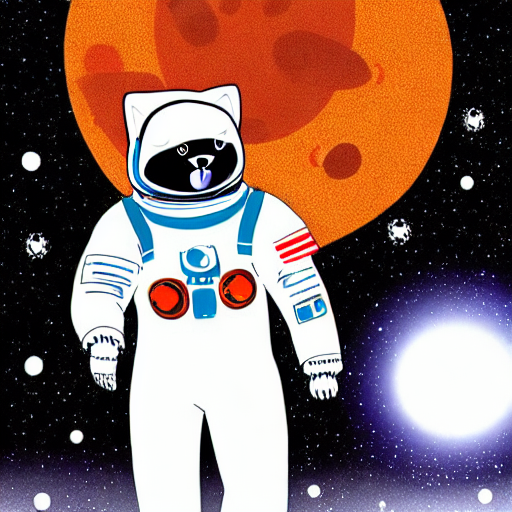

In [3]:
t0 = time.time()
img = gen(prompt)
print(f"생성 시간: {time.time()-t0:.1f}초")
img

이 한 줄(gen(prompt)) 안에서 일어나는 일은 논문 Figure 3의 아랫줄이에요.

1. 글자 → 숫자: τ_θ(CLIP 텍스트 인코더)가 프롬프트를 토큰 벡터들로 바꿔요.
2.시작 노이즈: seed 0으로 **64×64×4짜리 순수 노이즈 z_T**를 만들어요. 512×512 사진 크기가 아니라 latent 크기예요.
3. 걷어내기 25번: UNet이 z_t, 단계 t, 텍스트 벡터를 보고 노이즈를 예측해서 조금씩 빼요. 이때 cross-attention으로 "고양이", "우주복" 단어를 참고해요.
4. 크게 되살리기: 다 걷어낸 z_0를 디코더 D에 딱 한 번 넣어서 512×512 이미지로 만들어요.
- time.time()은 시작과 끝 시각을 재서 생성에 몇 초 걸렸는지 보려는 거예요.
- 마지막 줄의 img는 Colab이 그림을 화면에 띄우게 하는 거예요.

## 2. 걷어내기 횟수(steps) 바꿔 보기 ✅ 체크리스트 2

같은 seed = 같은 시작 노이즈. **걷어내기를 몇 번에 나눠 하느냐**만 바뀐다.
- steps가 적으면 빠르지만 거칠고, 많으면 느리지만 디테일이 산다 → 논문 5장 한계점 ①(반복 때문에 느리다)을 체감

steps=10: 1.9초
steps=25: 4.3초
steps=50: 7.7초


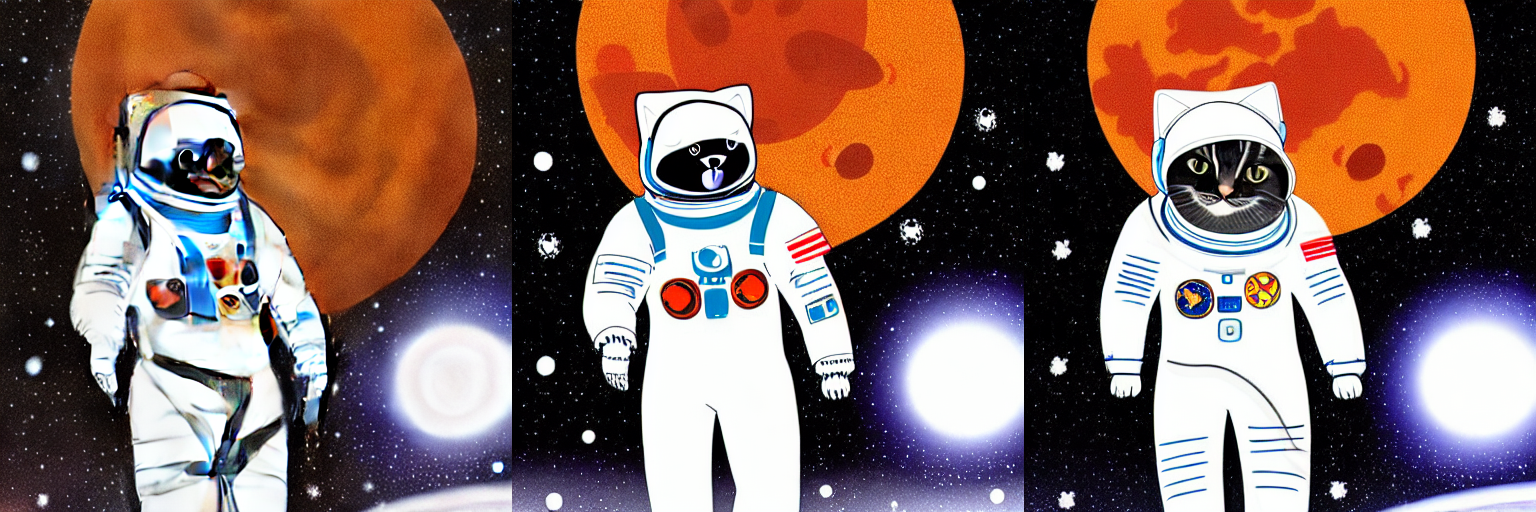

In [4]:
imgs, times = [], []
for s in [10, 25, 50]:
    t0 = time.time(); imgs.append(gen(prompt, steps=s)); times.append(time.time()-t0)
for s, t in zip([10, 25, 50], times):
    print(f"steps={s:>2}: {t:.1f}초")
make_image_grid(imgs, rows=1, cols=3)

- seed는 그대로 0이라서 세 그림 모두 **같은 노이즈 z_T**에서 출발해요.
- 바뀌는 건 노이즈를 몇 번에 나눠 걷어내느냐뿐이에요.
  - 10번: 한 번에 크게크게 걷어냄 → 빠르지만 거칠 수 있음
  - 50번: 조금씩 꼼꼼히 걷어냄 → 느리지만 디테일이 살 수 있음

< 논문과 연결 >

- 생성 시간은 UNet을 돌린 횟수에 거의 비례해요. 그래서 5장 한계점 ①("그림 한 장에 UNet을 수십~수백 번 반복해야 해서 GAN보다 느리다")을 직접 체감할 수 있어요.

- 원래 DDPM은 1000번 걷어냈어요. 여기서 10~50번으로 줄일 수 있는 건 **스케줄러(샘플러)**가 1000단계를 건너뛰며 계산해 주기 때문이에요. SANA 논문의 Flow-DPM-Solver도 바로 이 "더 적은 횟수로 걷어내기"를 개선한 거예요.

2단계 결과 해석

① 시간은 steps에 거의 비례해요
1.9초 → 4.3초 → 7.7초로, 한 번 걷어낼 때마다 약 0.16초씩 들어요. 1단계에서 7.4초가 나왔던 건 첫 실행이라 GPU 준비 시간이 섞여서 그래요. **”반복 횟수 = 비용"**이라는 5장 한계점 ①이 그대로 보여요.

② 디테일은 steps가 많을수록 또렷해요

10번: 우주복 형태는 있는데 얼굴이 뭉개졌고 고양이인지도 애매해요. 노이즈를 크게 크게 걷어내다 보니 세부를 다 못 채운 거예요.
25번: 깔끔해졌지만 얼굴이 검은 덩어리예요.
50번: 고양이 얼굴, 수염, 패치 무늬까지 제대로 나왔어요.

③ 그런데 큰 구도는 셋 다 똑같아요 ← 이게 제일 재밌는 포인트예요
주황 행성 위치, 오른쪽 아래 빛, 가운데 서 있는 우주인 자세가 세 장 모두 거의 같죠.

- **같은 seed = 같은 시작 노이즈 z_T**라서 구도가 노이즈 단계에서 이미 정해진 거예요.
- steps는 그 구도 위에 디테일을 얼마나 꼼꼼히 채우느냐만 바꿔요.
- Introduction Figure 2의 “의미(semantic)가 먼저 정해지고, 디테일(perceptual)은 나중에 채워진다”를 눈으로 본 셈이에요.

## 3. CFG(guidance_scale) 바꿔 보기 ✅ 체크리스트 3

CFG = "글자 조건을 얼마나 세게 따를지".
UNet을 **조건 있이 한 번, 조건 없이 한 번** 돌려서 그 차이를 키운다:
`예측 노이즈 = 조건없음 + cfg × (조건있음 − 조건없음)`
- 1: 글자를 거의 무시 → 프롬프트와 동떨어진 그림
- 5~8: 보통
- 15 이상: 글자를 과하게 따름 → 색이 타고 부자연스러워짐

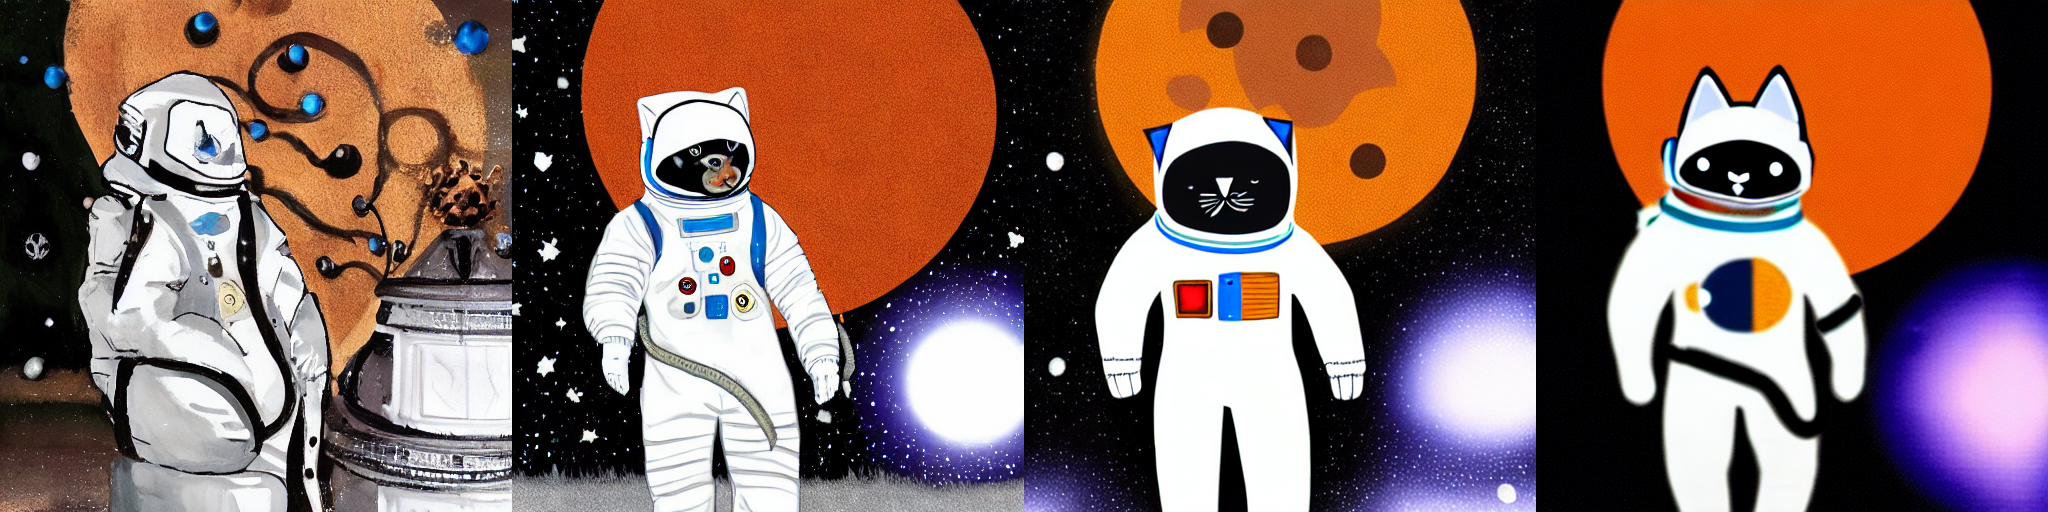

In [5]:
cfgs = [1, 5, 10, 20]
imgs = [gen(prompt, cfg=c) for c in cfgs]
make_image_grid(imgs, rows=1, cols=4)

CFG = 글자를 얼마나 세게 따를지 정하는 숫자예요. (Classifier-Free Guidance)

매 단계에서 UNet을 사실 두 번 돌려요.

- 조건 있이: "우주복 입은 고양이"를 보면서 노이즈 예측
- 조건 없이: 빈 프롬프트로 노이즈 예측

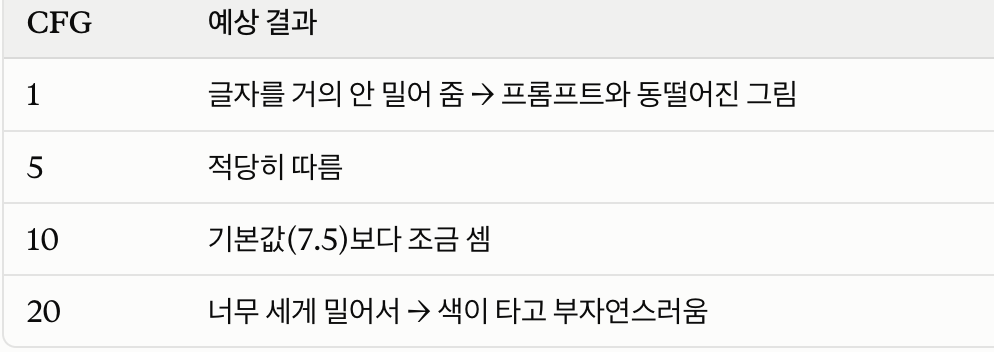

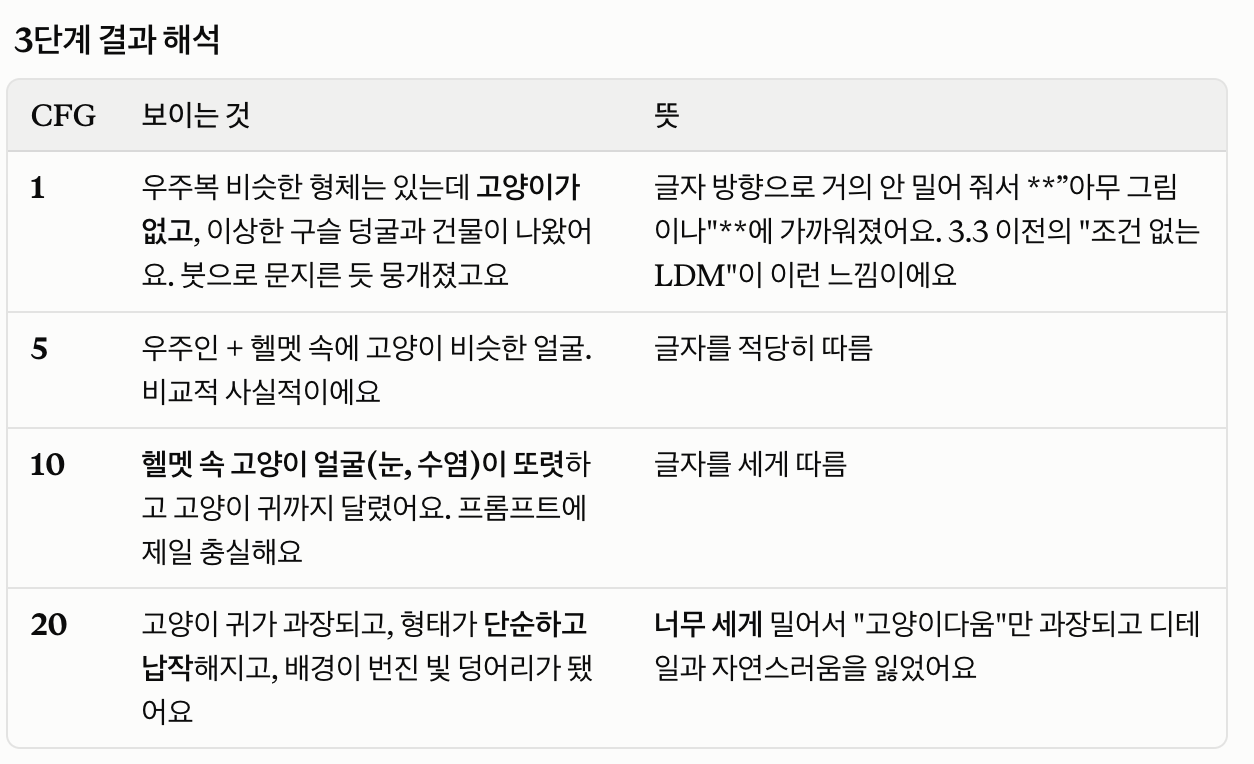


핵심: CFG를 올리면 프롬프트를 더 잘 따르는 대신 다양성과 자연스러움을 잃어요. 그래서 보통 7~8 근처를 써요. (기본값 7.5)

재밌는 점: steps 때와 달리 이번에는 구도도 조금씩 달라졌죠. CFG는 매 단계 걷어내는 방향 자체를 바꾸니까, 25번 반복하는 동안 차이가 쌓여서 결과가 점점 다른 곳으로 가요. steps는 "같은 길을 얼마나 꼼꼼히 가느냐", CFG는 “어느 방향으로 갈지”를 바꾸는 셈이에요.

## 4. 오토인코더(VAE)로 latent 직접 보기 ✅ 체크리스트 4

논문 3.1: `z = E(x)`, `x̃ = D(z)`, `f = H/h`
- Stable Diffusion의 오토인코더는 **KL-reg**, **f = 8**, **c = 4** → 512×512×3이 몇이 되는지 확인

x 모양: (1, 3, 512, 512) → 숫자 786432
z 모양: (1, 4, 64, 64) → 숫자 16384
f = 8,  48배 작음
z 표준편차: 스케일 전 5.73 → ×0.18215 후 1.04  (±1 근처로 맞추기!)


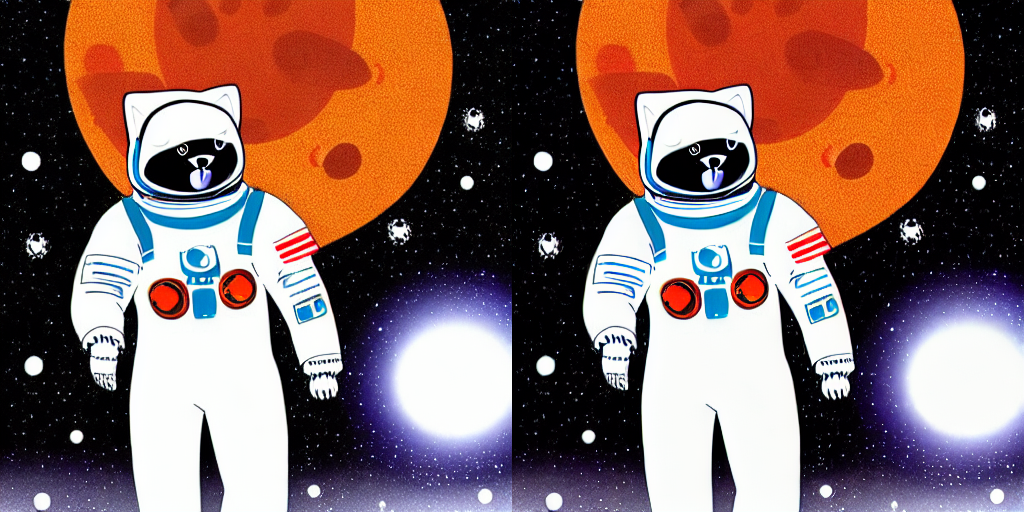

In [6]:
proc = pipe.image_processor
x = proc.preprocess(img).to("cuda", torch.float16)          # (1, 3, 512, 512), 값 범위 [-1, 1]

with torch.no_grad():
    z_raw = pipe.vae.encode(x).latent_dist.sample()          # E(x)
    sf = pipe.vae.config.scaling_factor                       # 0.18215
    z = z_raw * sf
    x_rec = pipe.vae.decode(z / sf).sample                   # D(z)

print("x 모양:", tuple(x.shape), "→ 숫자", x.numel())
print("z 모양:", tuple(z.shape), "→ 숫자", z.numel())
print(f"f = {x.shape[-1] // z.shape[-1]},  {x.numel() / z.numel():.0f}배 작음")
print(f"z 표준편차: 스케일 전 {z_raw.float().std():.2f} → ×{sf} 후 {z.float().std():.2f}  (±1 근처로 맞추기!)")

rec = proc.postprocess(x_rec, output_type="pil")[0]
make_image_grid([img, rec], rows=1, cols=2)   # 왼쪽 원본, 오른쪽 E→D 복원



```
x = proc.preprocess(img).to("cuda", torch.float16)
```
- 1단계에서 만든 고양이 그림을 숫자로 바꿔요. 모양은 **(1, 3, 512, 512)**이에요. 사진 1장, RGB 3채널, 512×512예요.
- 값 범위를 -1 ~ 1로 맞춰요.



```
z_raw = pipe.vae.encode(x).latent_dist.sample()   # E(x)
```
- **z = E(x)**예요. 인코더로 압축해요.
- latent_dist.sample(): KL-reg 오토인코더라서 인코더가 값 하나가 아니라 **분포(평균, 분산)**를 내놓고, 거기서 하나를 뽑아요. VAE랑 같은 방식이에요.



```
sf = pipe.vae.config.scaling_factor# 0.18215
z = z_raw * sf
```
3.1에서 본 **”latent 값을 ±1 근처로 맞추기"**예요. KL을 약하게만 걸어서 값이 아직 좀 크니까, 0.18215를 곱해서 크기를 맞춰요.



```
x_rec = pipe.vae.decode(z / sf).sample   # D(z)
```
**x̃ = D(z)**예요. 다시 나눠서 원래 크기로 돌린 다음 디코더로 복원해요.


출력에서 볼 것:

1. z 모양이 정말 **(1, 4, 64, 64)**인지 → f = 8, 채널 c = 4
2. 몇 배 작아졌는지 (48배가 나와야 해요)
3. 표준편차가 스케일 전에는 몇이고, 0.18215를 곱한 뒤에는 1 근처가 되는지
4. 원본과 복원 그림을 나란히 놓고, 복원에서 뭐가 달라졌는지 (5장 한계점 ②: "오토인코더 복원 품질이 상한선")




숫자가 논문에서 배운 그대로 나왔어요.

## 4단계 결과 해석

**① 크기: 512×512×3 → 64×64×4**
- 숫자 78.6만 개가 **1.6만 개**로, **48배** 작아졌어요.
- `f = 8` (가로세로를 각각 8배 줄임), 채널 `c = 4`. 처음 공부할 때 "Stable Diffusion은 `f = 8`, `c = 4`"라고 했던 게 바로 이 숫자예요.
- 그러니까 아까 2단계에서 UNet을 50번 돌린 건 전부 **64×64 작은 스케치북 위에서** 일어난 일이에요. 512×512에서 직접 했다면 훨씬 오래 걸렸을 거예요.

**② 표준편차: 5.73 → 1.04** ← 3.1 regularization을 숫자로 확인
- KL을 **아주 약하게**만 걸었기 때문에, 인코더가 낸 값은 퍼짐이 약 5.7로 꽤 커요.
- 그대로 쓰면 "값이 너무 커서 노이즈 1000번 섞어도 원본이 남는" 문제(경우 A)가 생겨요.
- 그래서 0.18215를 곱했더니 **딱 1 근처**가 됐어요. diffusion의 노이즈 규칙 `N(0, 1)`과 크기가 맞아진 거예요.

**③ 복원: 거의 똑같아요**
- 48배나 줄였다가 되살렸는데 구도, 색, 고양이 얼굴, 우주복 패치까지 다 살아 있어요. 이게 **"perceptual 디테일만 빼고 보기엔 똑같은 버전"**이에요.
- 확대해서 비교하면 **작은 별 점, 행성 표면의 오톨도톨한 질감, 패치 안의 작은 글씨** 같은 아주 미세한 부분이 살짝 뭉개졌을 수 있어요. 이게 5장 한계점 ②("LDM은 오토인코더가 복원할 수 있는 품질을 넘을 수 없다")예요. 이 그림에서는 거의 티가 안 나지만, 아주 정밀한 작업에서는 이 차이가 상한선이 돼요.

---

## latent 4채널 그림

아래 셀(`channel 0 ~ 3`)도 실행해 보셨어요? 아직이면 실행해서 보여 주세요. 64×64 숫자 격자 4장이 나오는데, **색이 아닌데도 고양이 우주인 윤곽이 희미하게 보이는지**가 포인트예요. 보인다면 latent가 2D 구조를 그대로 유지한다는 증거예요.

그다음은 보너스 두 개(노이즈가 걷히는 과정, 텍스트 인코더 크기)만 남았어요.

### latent 4개 채널 그려 보기
latent는 색이 아니라 **오토인코더가 스스로 정한 요약 정보**. 그래도 2D 격자라서 대충 원본 모양이 보인다 (논문 3.1의 "2D 구조 유지").

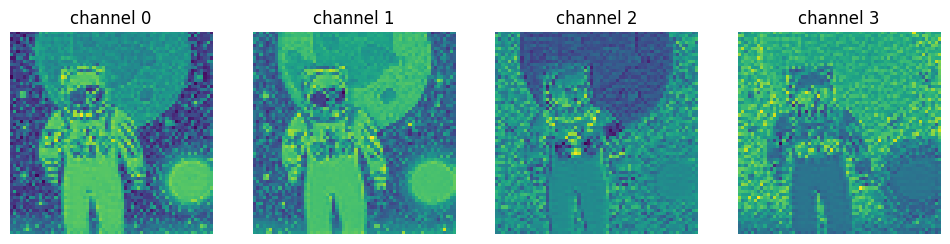

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    ax[i].imshow(z[0, i].float().cpu(), cmap="viridis"); ax[i].set_title(f"channel {i}"); ax[i].axis("off")
plt.show()

latent 4채널 해석

① 2D 구조가 그대로 살아 있어요
64×64 숫자 격자인데도 우주인, 행성, 오른쪽 아래 빛 덩어리가 원래 자리에 그대로 있어요. 칸 (10, 20)의 숫자가 원본 사진의 (80, 160) 근처 정보를 담고 있다는 뜻이에요. 이게 3.1에서 말한 “2D 격자 구조 유지”이고, 그래서 UNet(convolution)이 사진 다루듯 이 latent를 다룰 수 있어요. 한 줄로 폈다면 이런 그림이 안 나왔겠죠.

② 채널마다 담는 정보가 달라요

- channel 0, 1: 행성과 우주복이 밝게 나와서 원본의 밝기와 비슷한 느낌이에요.
- channel 2: 행성이 오히려 어둡게 나와요. 다른 성분(색 차이 같은 것)을 담고 있는 것 같아요.
- channel 3: 행성이 거의 안 보이고 우주인 윤곽과 배경 질감 위주예요.

다만 이 해석은 추측이에요. 채널마다 뭘 담을지는 사람이 정한 게 아니라 오토인코더가 "복원이 잘 되는 방식"으로 스스로 정한 거라서, 정확한 의미는 딱 잘라 말할 수 없어요. 그래서 논문에서도 latent를 "색"이 아니라 그냥 "표현(representation)"이라고 불러요.

③ 자글자글한 점들
배경의 별, 작은 질감 같은 미세한 디테일이 이렇게 점처럼 압축돼 있어요. 64×64 안에 다 담기엔 작아서, 디코더가 복원할 때 이 부분이 살짝 뭉개질 수 있어요. 아까 본 한계점 ②와 연결돼요.

## 5. (보너스) 노이즈가 걷히는 과정 보기 — DDPM Figure 2를 실제로

매 단계의 latent `z_t`를 디코더로 펴서 본다.

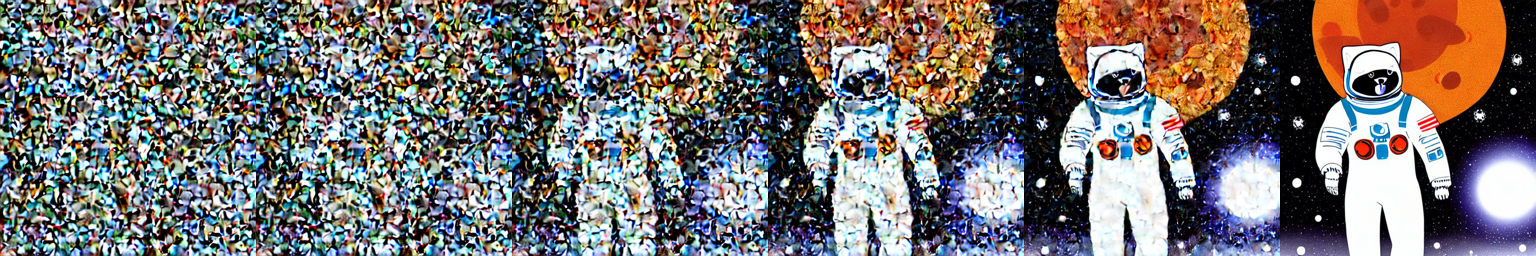

In [8]:
snaps = []
def cb(p, step, timestep, kw):
    if step in (0, 4, 9, 14, 19, 24):
        with torch.no_grad():
            im = p.vae.decode(kw["latents"] / p.vae.config.scaling_factor).sample
        snaps.append(proc.postprocess(im, output_type="pil")[0].resize((256, 256)))
    return kw

_ = gen(prompt, steps=25, callback_on_step_end=cb, callback_on_step_end_tensor_inputs=["latents"])
make_image_grid(snaps, rows=1, cols=len(snaps))   # 왼쪽 = 초반(노이즈) → 오른쪽 = 완성



```
def cb(p, step, timestep, kw):
    if step in (0, 4, 9, 14, 19, 24):
        im = p.vae.decode(kw["latents"] / p.vae.config.scaling_factor).sample
```
- callback: 그림을 만드는 도중에 매 단계마다 잠깐 끼어들어서 무언가를 하게 하는 함수예요.
- 여기서는 25단계 중 6번(0, 4, 9, 14, 19, 24번째) 끼어들어서, 그 순간의 latent z_t를 - 디코더로 펴서 사진으로 저장해요.
- 원래는 마지막에 D를 딱 한 번만 쓰지만, 구경하려고 중간에도 몇 번 써 보는 거예요.

------------------------

볼 것: 처음에 맨 앞에서 본 DDPM Figure 2 그림(지지직 → 스마일)이 진짜 모델에서도 똑같이 일어나는지요.

- 초반: 거의 노이즈인데 큰 색 덩어리(주황 행성, 흰 우주복 자리)가 먼저 잡히는지
- 중반: 형태(우주인, 고양이 귀)가 나타나는지
- 후반: 얼굴, 패치 같은 디테일이 채워지는지



5단계 결과 해석
단계	보이는 것	뜻
0	알록달록한 모자이크뿐	거의 순수 노이즈 z_T
4	가운데가 살짝 밝아짐	흰 우주복 자리가 잡히기 시작
9	우주인 실루엣 등장	**큰 형태(semantic)**가 정해짐
14	주황 행성, 우주복, 얼굴 위치	구도 완성, 색이 자리 잡음
19	패치, 헬멧, 별	디테일(perceptual) 채우는 중
24	깔끔한 완성본	z_0 → 디코더

① "구도 먼저, 디테일 나중"이 시간 순서로 보여요
9단계쯤에 이미 우주인이 가운데 서 있다는 게 정해지고, 그 뒤로는 그 위에 디테일만 덧칠해요. Introduction Figure 2의 semantic → perceptual 순서가 생성 과정 안에서도 똑같이 일어나는 거예요.

② 노이즈가 TV 지지직이 아니라 "모자이크"예요 ← 재밌는 포인트
맨 처음 DDPM 설명 그림에서는 노이즈가 흑백 지지직이었죠. 그런데 여기서는 알록달록한 붓터치 모자이크예요. 노이즈를 사진이 아니라 latent에 섞었기 때문이에요. latent의 랜덤 숫자를 디코더 D로 펴면, 디코더가 "사진 조각 같은 질감"으로 해석해서 이런 모양이 나와요. diffusion이 픽셀이 아니라 latent 공간에서 일어난다는 걸 눈으로 확인한 셈이에요.

③ 마지막 그림 = 1단계 그림
24번째 결과가 맨 처음 만든 고양이(혀 내민 얼굴)랑 똑같죠. 같은 seed, 같은 25 steps니까 같은 길을 걸어서 같은 곳에 도착한 거예요.

## 6. (보너스) 텍스트 인코더 τ_θ 출력 크기

논문 3.3: `τ_θ(y) ∈ R^{M × d_τ}` → Stable Diffusion에서 M, d_τ는?

In [9]:
tok = pipe.tokenizer(prompt, padding="max_length", max_length=pipe.tokenizer.model_max_length, return_tensors="pt")
with torch.no_grad():
    emb = pipe.text_encoder(tok.input_ids.to("cuda"))[0]
print("τ_θ(y) 모양:", tuple(emb.shape), "→ M = 토큰 수, d_τ = 벡터 길이")
print("UNet cross-attention이 받는 K, V 차원:", pipe.unet.config.cross_attention_dim)

τ_θ(y) 모양: (1, 77, 768) → M = 토큰 수, d_τ = 벡터 길이
UNet cross-attention이 받는 K, V 차원: 768




```
tok = pipe.tokenizer(prompt, padding="max_length", max_length=pipe.tokenizer.model_max_length, return_tensors="pt")
emb = pipe.text_encoder(tok.input_ids.to("cuda"))[0]
```
- tokenizer: 프롬프트를 토큰(단어 조각) 번호들로 쪼개요. max_length까지 빈칸으로 채워서 항상 같은 길이로 맞춰요.
- text_encoder: CLIP 텍스트 인코더예요. 토큰 번호를 토큰마다 벡터 하나씩으로 바꿔요. 3.3의 τ_θ(y)가 바로 이거예요.


출력에서 볼 것:

1. τ_θ(y) 모양 (1, M, d_τ) → M(토큰 수)과 d_τ(벡터 길이)가 몇인지
2. cross_attention_dim → UNet의 cross-attention이 받는 K, V 차원. d_τ와 같은 숫자인지 (같아야 글자를 K, V로 넣을 수 있어요)


6단계 결과 해석

τ_θ(y) = (1, 77, 768)

- M = 77: 토큰이 77개예요. 프롬프트가 77단어라는 뜻은 아니에요. 실제 프롬프트는 20개 남짓인데, CLIP 텍스트 인코더는 항상 77칸을 받게 만들어져 있어서 나머지를 빈칸(padding)으로 채운 거예요. 그래서 Stable Diffusion 프롬프트는 77토큰을 넘으면 뒷부분이 잘려요.
- d_τ = 768: 토큰 하나를 숫자 768개짜리 벡터로 나타내요. 1주차 CLIP(ViT-L/14)의 텍스트 인코더 크기 그대로예요.

cross_attention_dim = 768
UNet의 cross-attention이 K, V로 받는 차원이 텍스트 벡터 길이와 똑같아요. 그래서 K = W_K · τ_θ(y), V = W_V · τ_θ(y)가 바로 계산돼요. 3.3 수식이 코드에서 이렇게 맞물려 있는 거예요.

크기로 다시 보면: UNet 첫 층에서 그림 쪽 칸은 64×64 = 4096개예요. 그러니까 QK^T 점수표는 4096 × 77이에요. 칸 4096개가 각자 77개 토큰 중 어디를 볼지 정하는 거죠. (아까 cross-attention 그림의 4×4 칸, 토큰 5개를 진짜 크기로 키운 버전이에요.)

## 정리 (Notion용)

- latent 크기: 512×512×3 → 64×64×4 (f = 8, 48배 작음)
- latent 표준편차: 스케일 전 5.73 → ×0.18215 후 1.04 (노이즈 N(0,1)과 크기 맞추기)
- steps 10 / 25 / 50 생성 시간: 1.9 / 4.3 / 7.7초 → 반복 횟수에 비례. steps가 많을수록 고양이 얼굴과 디테일이 또렷. 같은 seed라 구도는 셋 다 동일
- CFG: 1이면 고양이가 안 나오고 엉뚱한 그림, 10에서 프롬프트에 가장 충실, 20이면 형태가 과장되고 납작해짐
- VAE 복원: 48배 압축했는데도 거의 똑같음. 미세한 별·질감 정도만 살짝 손실 가능
- latent 채널: 색이 아닌데도 2D 구조가 그대로 보임 → UNet이 다루기 좋은 이유
- 생성 과정: 9단계쯤 구도가 정해지고 그 뒤로 디테일이 채워짐. latent 노이즈를 디코딩하면 지지직이 아니라 모자이크처럼 보임
- τ_θ(y): (1, 77, 768) = 토큰 77개 × 768차원 = UNet cross_attention_dim(768)

✅ 마지막: `파일 → 사본을 GitHub에 저장`으로 레포에 커밋